# Task 3.2: Evaluate recommendation models after reranking

This notebook evaluates the Task 3.1 rerankers on the same MovieLens 100K test split and with the same metrics as Task 2.1. It reports both accuracy and beyond-accuracy metrics, then makes the trade-off explicit by comparing every reranked list with its unre-ranked base model.

**Protocol.** Models are trained with the Task 1 split (`seed=2020`), recommendations are generated from each user's top-100 candidate pool, and all lists have `K=10` items. Held-out test items are used only for evaluation, never by a reranker. The beyond-accuracy metrics are ILD, novelty, MC_KL, UPD, ARP, APLT, catalogue coverage, exposure Gini, and head/tail exposure from `group_18/metrics.py`.

The notebook uses MMR, Steck (2018), xQuAD, and UGF from `group_18/rerankers.py`. For the first three, `lambda=0` is the base ranking and larger lambda gives more weight to the beyond-accuracy objective. UGF uses its Task 3.1 `epsilon` constraint instead of lambda.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from metrics import K, evaluate_beyond_accuracy, evaluate_topk, item_popularity, short_head_mask
from recbole_utils import ROOT, build_model, load_split, model_scores, top_k
from rerankers import mmr, steck_2018_re_rank, xquad, ugf, rerank_all

RESULTS_DIR = ROOT / "group_18" / "results" / "task_3_2"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
N_CANDIDATES = 100
LAMBDAS = (0.0, 0.25, 0.5, 0.75, 1.0)
UGF_EPSILONS = (0.05, 0.10)

# These are tuned/traditional models used in Task 2.2. Add BPR or FISM when a full rerun is desired.
MODEL_SPECS = {
    "ItemKNN": ("ItemKNN", "ItemKNN", {"k": 100, "shrink": 100}),
    "SLIMElastic": ("SLIMElastic", "SLIMElastic", {"alpha": 0.1, "l1_ratio": 0.1}),
    "EASE": ("EASE", "EASE", {"reg_weight": 250.0}),
}
RERANKERS = {
    "MMR": (mmr, {}),
    "Steck": (steck_2018_re_rank, {}),
    "xQuAD": (xquad, {"smooth": True}),
}
assert len(MODEL_SPECS) >= 2

## 1. Load the common split and item/user context

RecBole uses item id `0` for padding. The rerankers therefore receive padded genre and popularity context, while the Task 2.1 metrics receive zero-based item ids (`internal_id - 1`). This keeps the score matrix and all reranker context aligned.

In [2]:
config, dataset, train_data, valid_data, test_data = load_split("SLIMElastic")
UID, IID = dataset.uid_field, dataset.iid_field
N_USERS, N_INTERNAL_ITEMS = dataset.user_num, dataset.item_num
N_ITEMS = N_INTERNAL_ITEMS - 1

train_inter = train_data.dataset.inter_feat
train_users = train_inter[UID].numpy()
train_items = train_inter[IID].numpy() - 1
pop = item_popularity(train_users, train_items, N_ITEMS)
history = pd.Series(train_items).groupby(train_users).apply(np.asarray).to_dict()

test_inter = test_data.dataset.inter_feat
test_items = pd.Series(test_inter[IID].numpy() - 1).groupby(test_inter[UID].numpy()).apply(set).to_dict()
eval_users = np.array(sorted(test_items), dtype=int)
histories = [history.get(int(u), np.array([], dtype=int)) for u in eval_users]

# RecBole may drop the raw `class` sequence field from get_item_feature().
# Parse the repository's MovieLens item file and map raw ids to RecBole ids.
item_file = ROOT / "dataset" / "ml-100k" / "ml-100k.item"
item_table = pd.read_csv(item_file, sep="\t")
genre_names = sorted({genre for value in item_table["class:token_seq"] for genre in str(value).split()})
genre_index = {genre: i for i, genre in enumerate(genre_names)}
genres_padded = np.zeros((N_INTERNAL_ITEMS, len(genre_names)), dtype=float)
item_token_map = dataset.field2token_id[IID]
for raw_item, genre_value in zip(item_table["item_id:token"], item_table["class:token_seq"]):
    internal_item = item_token_map.get(str(int(raw_item)))
    if internal_item is None:
        raise KeyError(f"Item {raw_item} is missing from RecBole's item-id mapping.")
    for genre in str(genre_value).split():
        genres_padded[internal_item, genre_index[genre]] = 1.0
if np.any(genres_padded[1:].sum(axis=1) == 0):
    raise RuntimeError("At least one MovieLens item has no parsed genre.")
genres_zero_based = genres_padded[1:]
head_zero_based = short_head_mask(pop, frac=0.2)
head_padded = np.r_[False, head_zero_based]

profile_sizes = pd.Series({u: len(h) for u, h in history.items()})
active_threshold = profile_sizes.quantile(0.8)
active_users = np.array([len(history.get(int(u), [])) >= active_threshold for u in eval_users])
user_groups = {"active_users": active_users, "cold_users": ~active_users}
print(f"{N_USERS} users, {N_ITEMS} items, {len(eval_users)} evaluated users, K={K}")

944 users, 1682 items, 943 evaluated users, K=10


## 2. Score the base models

The score matrices use `-inf` for padding and interacted items, matching the candidate convention required by `candidate_pool`. The base top-10 lists are retained as the reference for every accuracy and beyond-accuracy delta.

In [3]:
base_scores = {}
base_accuracy = {}
for name, (model_name, config_name, overrides) in MODEL_SPECS.items():
    print(f"Training/scoring {name}...")
    net, _, model_dataset, _, _, model_test = build_model(model_name, config_name, **overrides)
    scores, model_test_items = model_scores(net, model_dataset, model_test)
    missing = set(test_items) ^ set(model_test_items)
    if missing:
        raise ValueError(f"Test-user mismatch for {name}: {len(missing)} users")
    base_scores[name] = scores
    base_accuracy[name] = evaluate_topk(
        {u: [item - 1 for item in top_k(scores, [u], K + 1)[0] if item > 0][:K] for u in eval_users},
        test_items,
        ks=(K,),
    )

base_accuracy_table = pd.DataFrame({
    name: result["topk"][f"@{K}"] for name, result in base_accuracy.items()
}).T
display(base_accuracy_table[["ndcg", "recall", "precision", "mrr"]])

Training/scoring ItemKNN...


Training/scoring SLIMElastic...


Training/scoring EASE...


metric,ndcg,recall,precision,mrr
ItemKNN,0.281920,0.240213,0.183033,0.482669
SLIMElastic,0.310771,0.264639,0.207105,0.511346
EASE,0.329506,0.280506,0.220573,0.527707


## 3. Apply Task 3.1 rerankers and evaluate Task 2.1 metrics

The same candidate pool, users, cutoff, histories, genres, and popularity split are used for every method. `evaluate_topk` supplies the accuracy metrics; `evaluate_beyond_accuracy` supplies the beyond-accuracy metrics. In the tables, `delta_*` is reranked minus base for the same model, so positive values are improvements for higher-is-better metrics and negative values are improvements for lower-is-better metrics.

In [4]:
rows = []
per_user_results = {}
for model_name, scores in base_scores.items():
    base_recs_internal = np.array([[item for item in top_k(scores, [u], K + 1)[0] if item > 0][:K] for u in eval_users])
    base_recs = base_recs_internal - 1
    base_acc = evaluate_topk({u: r.tolist() for u, r in zip(eval_users, base_recs)}, test_items, ks=(K,))
    base_beyond, base_beyond_pu = evaluate_beyond_accuracy(
        base_recs, histories, genres_zero_based, pop, N_USERS,
        user_groups=user_groups, accuracy=base_acc["per_user"][f"ndcg@{K}"].to_numpy()
    )

    def record(label, recs, accuracy_result, beyond_summary, beyond_pu, parameter):
        acc = accuracy_result["topk"][f"@{K}"]
        row = {"model": model_name, "method": label, "parameter": parameter}
        row.update({f"accuracy_{k}": v for k, v in acc.items()})
        row.update(beyond_summary.to_dict())
        row.update({f"delta_{metric}": acc[metric] - base_acc["topk"][f"@{K}"][metric] for metric in acc.index})
        row.update({f"delta_{k}": beyond_summary[k] - base_beyond[k] for k in beyond_summary.index})
        rows.append(row)
        per_user_results[(model_name, label, parameter)] = (recs, accuracy_result["per_user"], beyond_pu)

    record("Base", base_recs, base_acc, base_beyond, base_beyond_pu, 0.0)
    for label, (rerank, context) in RERANKERS.items():
        for lam in LAMBDAS:
            kwargs = {k: v for k, v in context.items()}
            kwargs.update({"genres": genres_padded} if label in ("MMR", "Steck") else {"short_head": head_padded})
            rerank_histories = ({u: history.get(int(u), np.array([], dtype=int)) + 1 for u in eval_users}
                                if label == "Steck" else None)
            recs_internal = np.asarray(rerank_all(
                rerank, scores, eval_users, K, lam, n_candidates=N_CANDIDATES,
                histories=rerank_histories, **kwargs
            ))
            recs = recs_internal - 1
            acc = evaluate_topk({u: r.tolist() for u, r in zip(eval_users, recs)}, test_items, ks=(K,))
            beyond, beyond_pu = evaluate_beyond_accuracy(
                recs, histories, genres_zero_based, pop, N_USERS,
                user_groups=user_groups, accuracy=acc["per_user"][f"ndcg@{K}"].to_numpy()
            )
            record(label, recs, acc, beyond, beyond_pu, lam)

    for eps in UGF_EPSILONS:
        recs_internal = ugf(scores, eval_users, K, eps, active_users, n_candidates=N_CANDIDATES)
        recs = recs_internal - 1
        acc = evaluate_topk({u: r.tolist() for u, r in zip(eval_users, recs)}, test_items, ks=(K,))
        beyond, beyond_pu = evaluate_beyond_accuracy(
            recs, histories, genres_zero_based, pop, N_USERS,
            user_groups=user_groups, accuracy=acc["per_user"][f"ndcg@{K}"].to_numpy()
        )
        record("UGF", recs, acc, beyond, beyond_pu, eps)

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "reranker_evaluation.csv", index=False)
display(results[["model", "method", "parameter", "accuracy_ndcg", "accuracy_recall", f"ild@{K}", f"novelty@{K}", f"mc_kl@{K}", f"coverage@{K}", f"gini@{K}"]].head(20))

,model,method,parameter,accuracy_ndcg,accuracy_recall,ild@10,novelty@10,mc_kl@10,coverage@10,gini@10
0,ItemKNN,Base,0.00,0.281920,0.240213,0.730788,1.975881,0.776379,0.153983,0.945038
1,ItemKNN,MMR,0.00,0.281920,0.240213,0.730788,1.975881,0.776379,0.153983,0.945038
2,ItemKNN,MMR,0.25,0.278394,0.234336,0.774467,1.988595,0.635598,0.157551,0.944353
3,ItemKNN,MMR,0.50,0.259623,0.217593,0.856754,2.134289,0.540188,0.169441,0.939948
4,ItemKNN,MMR,0.75,0.232092,0.184817,0.899751,2.320696,0.531835,0.189655,0.934409
5,ItemKNN,MMR,1.00,0.212542,0.155907,0.907891,2.455099,0.508946,0.214031,0.925545
6,ItemKNN,Steck,0.00,0.281920,0.240213,0.730788,1.975881,0.776379,0.153983,0.945038
7,ItemKNN,Steck,0.25,0.278169,0.245853,0.742690,1.980036,0.585935,0.158740,0.944094
8,ItemKNN,Steck,0.50,0.247723,0.238774,0.747778,2.012606,0.429141,0.172414,0.940562
9,ItemKNN,Steck,0.75,0.217262,0.225166,0.760337,2.111445,0.256104,0.202140,0.932278


## 4. Beyond-accuracy performance

The following table focuses on the metrics targeted by the rerankers. Higher ILD, novelty, APLT, and coverage indicate more variety, less popularity concentration, more long-tail exposure, and broader catalogue use. Lower MC_KL, UPD, ARP, and Gini indicate better calibration, closer popularity-profile matching, lower average popularity, and more equal exposure. An exposure ratio closer to one means better head/tail parity.

In [5]:
beyond_cols = [f"ild@{K}", f"novelty@{K}", f"mc_kl@{K}", f"upd@{K}", f"arp@{K}", f"aplt@{K}", f"coverage@{K}", f"gini@{K}", f"exposure_ratio@{K}"]
display(results[results.method != "Base"].set_index(["model", "method", "parameter"])[beyond_cols].round(4))

base_rows = results[results.method == "Base"].set_index("model")
for metric in [f"ild@{K}", f"novelty@{K}", f"mc_kl@{K}", f"coverage@{K}", f"gini@{K}", f"aplt@{K}"]:
    results[f"delta_{metric}"] = results.apply(lambda r: r[metric] - base_rows.loc[r.model, metric], axis=1)
delta_cols = [f"delta_{m}" for m in [f"ild@{K}", f"novelty@{K}", f"mc_kl@{K}", f"coverage@{K}", f"gini@{K}", f"aplt@{K}"]]
display(results[results.method != "Base"].groupby("method")[delta_cols].mean().round(4))

ild@10  novelty@10  mc_kl@10  upd@10  arp@10  \
model       method parameter                                                 
ItemKNN     MMR    0.00       0.7308      1.9759    0.7764  0.2272  0.2678   
                   0.25       0.7745      1.9886    0.6356  0.2134  0.2660   
                   0.50       0.8568      2.1343    0.5402  0.1550  0.2472   
                   0.75       0.8998      2.3207    0.5318  0.1204  0.2261   
                   1.00       0.9079      2.4551    0.5089  0.1084  0.2110   
            Steck  0.00       0.7308      1.9759    0.7764  0.2272  0.2678   
                   0.25       0.7427      1.9800    0.5859  0.2235  0.2673   
                   0.50       0.7478      2.0126    0.4291  0.2036  0.2630   
                   0.75       0.7603      2.1114    0.2561  0.1663  0.2508   
                   1.00       0.7408      2.6618    0.0874  0.1098  0.1791   
            xQuAD  0.00       0.7308      1.9759    0.7764  0.2272  0.2678   
                   0.25       0.7299      1.9843    0.7746  0.2262  0.2670   
                   0.50       0.7285      2.0827    0.7780  0.2153  0.2576   
                   0.75       0.7183      2.3240    0.7993  0.1814  0.2334   
                   1.00       0.7135      2.4768    0.8071  0.1680  0.2181   
            UGF    0.05       0.7308      1.9759    0.7764  0.2272  0.2678   
                   0.10       0.7308      1.9759    0.7764  0.2272  0.2678   
SLIMElastic MMR    0.00       0.7343      2.0485    0.6884  0.1788  0.2586   
                   0.25       0.7853      2.0580    0.5484  0.1742  0.2577   
                   0.50       0.8649      2.2000    0.4816  0.1389  0.2409   
                   0.75       0.8970      2.3406    0.4739  0.1180  0.2239   
                   1.00       0.9048      2.4730    0.4639  0.1038  0.2079   
            Steck  0.00       0.7343      2.0485    0.6884  0.1788  0.2586   
                   0.25       0.7470      2.0490    0.5297  0.1771  0.2587   
                   0.50       0.7518      2.0852    0.3767  0.1674  0.2545   
                   0.75       0.7579      2.1764    0.2354  0.1444  0.2437   
                   1.00       0.7355      2.7089    0.0809  0.1009  0.1748   
            xQuAD  0.00       0.7343      2.0485    0.6884  0.1788  0.2586   
                   0.25       0.7319      2.0735    0.6908  0.1765  0.2562   
                   0.50       0.7290      2.2836    0.6882  0.1500  0.2356   
                   0.75       0.7220      2.5900    0.7045  0.1127  0.2051   
                   1.00       0.7174      2.7961    0.7307  0.0960  0.1845   
            UGF    0.05       0.7343      2.0485    0.6884  0.1788  0.2586   
                   0.10       0.7343      2.0485    0.6884  0.1788  0.2586   
EASE        MMR    0.00       0.7279      2.1069    0.7070  0.1606  0.2509   
                   0.25       0.7821      2.1157    0.5514  0.1570  0.2501   
                   0.50       0.8718      2.3012    0.4728  0.1179  0.2311   
                   0.75       0.9061      2.4712    0.4805  0.0944  0.2126   
                   1.00       0.9142      2.6081    0.4703  0.0844  0.1974   
            Steck  0.00       0.7279      2.1069    0.7070  0.1606  0.2509   
                   0.25       0.7422      2.1079    0.5340  0.1600  0.2509   
                   0.50       0.7460      2.1484    0.3847  0.1496  0.2465   
                   0.75       0.7556      2.2333    0.2359  0.1283  0.2371   
                   1.00       0.7359      2.8271    0.0799  0.0835  0.1660   
            xQuAD  0.00       0.7279      2.1069    0.7070  0.1606  0.2509   
                   0.25       0.7248      2.1498    0.7067  0.1546  0.2470   
                   0.50       0.7174      2.3785    0.7194  0.1233  0.2255   
                   0.75       0.7130      2.6821    0.7368  0.0893  0.1963   
                   1.00       0.7094      2.9007    0.7597  0.0709  0.1751   
            UGF    0.05       0.7279      2.1069    

,delta_ild@10,delta_novelty@10,delta_mc_kl@10,delta_coverage@10,delta_gini@10,delta_aplt@10
method,,,,,,
MMR,0.1062,0.1961,-0.1685,0.0184,-0.0062,0.0411
Steck,0.0127,0.1718,-0.3247,0.0348,-0.0132,0.0368
UGF,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
xQuAD,-0.0078,0.2798,0.0139,0.0569,-0.0215,0.1747


## 5. Accuracy versus beyond-accuracy trade-off

A reranker is useful when it moves a beyond-accuracy metric in the desired direction without an unacceptable accuracy loss. The plots below show this directly for each model. The dashed point is the unre-ranked base model; arrows along each lambda curve show how increasing the reranking strength changes the operating point.

Typical interpretations are: MMR should move right on ILD, Steck should move left on MC_KL, and xQuAD should move toward more long-tail exposure/coverage. A point below and to the right of the base point on an accuracy-vs-beyond-accuracy plot is a clear trade-off; a point above and to the right is a Pareto improvement. The actual conclusion must be read from the generated values rather than assumed from the objective.

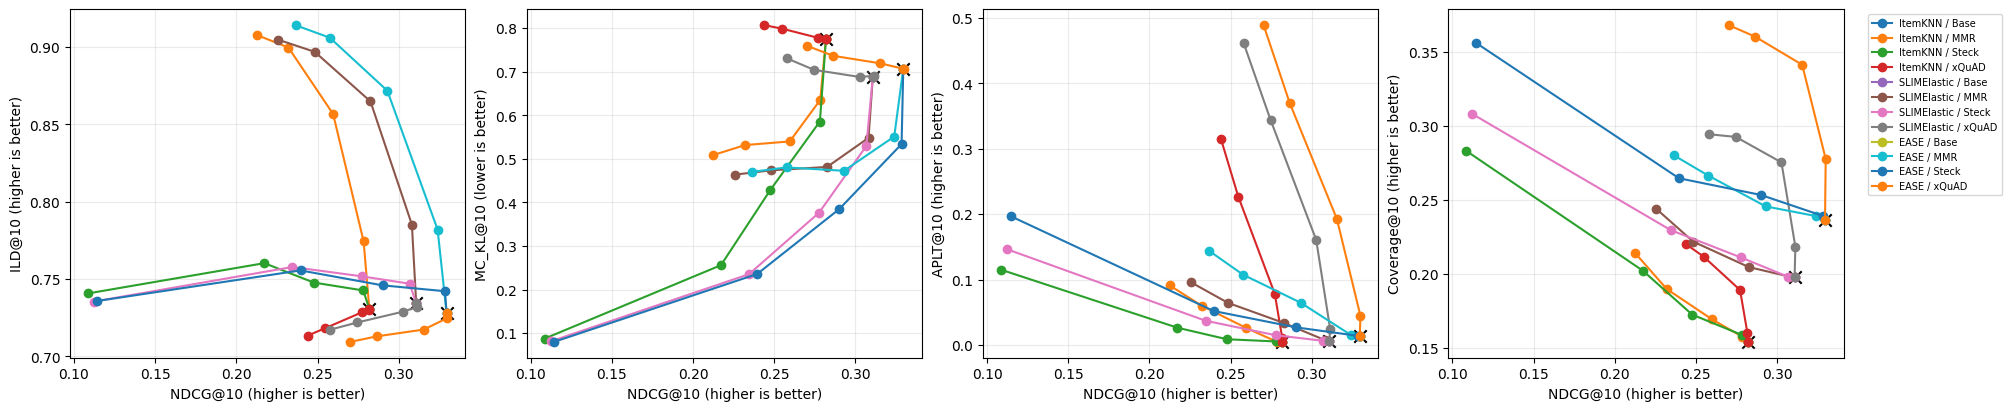

In [6]:
plot_specs = [
    (f"ild@{K}", "ILD@10 (higher is better)"),
    (f"mc_kl@{K}", "MC_KL@10 (lower is better)"),
    (f"aplt@{K}", "APLT@10 (higher is better)"),
    (f"coverage@{K}", "Coverage@10 (higher is better)"),
]
fig, axes = plt.subplots(1, len(plot_specs), figsize=(20, 4), constrained_layout=True)
for ax, (x_metric, x_label) in zip(axes, plot_specs):
    for model_name in MODEL_SPECS:
        subset = results[(results.model == model_name) & (results.method != "UGF")]
        for method, group in subset.groupby("method"):
            group = group.sort_values("parameter")
            ax.plot(group["accuracy_ndcg"], group[x_metric], marker="o", label=f"{model_name} / {method}")
        base = results[(results.model == model_name) & (results.method == "Base")].iloc[0]
        ax.scatter(base["accuracy_ndcg"], base[x_metric], marker="x", s=80, color="black")
    ax.set_xlabel("NDCG@10 (higher is better)")
    ax.set_ylabel(x_label)
    ax.grid(alpha=0.25)
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.savefig(RESULTS_DIR / "accuracy_beyond_accuracy_tradeoffs.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Discussion

Use the tables and plots above to write the final discussion:

1. **Beyond accuracy:** identify which reranker improves its intended metric and whether the improvement generalises to related metrics (for example, MMR's ILD/coverage, Steck's MC_KL/UPD, or xQuAD's APLT/exposure ratio). Also note any metric that worsens, since diversity or novelty can increase while calibration or exposure equality decreases.
2. **Accuracy cost:** compare `accuracy_ndcg`, `accuracy_recall`, and `accuracy_mrr` with the matching base row. Lambda curves make the gradual cost visible; UGF's epsilon curve shows the analogous fairness-quality constraint.
3. **Trade-off conclusion:** select an operating point rather than automatically choosing lambda=1. Prefer a Pareto-improving point when available; otherwise report the largest beyond-accuracy gain whose accuracy decrease is acceptable for the application. This is the central result of Task 3.2: reranking changes the objective from accuracy-only optimisation to an explicit accuracy/utility trade-off.